# Classificação binária de candidatos a pulsares (HTRU2)

**Disciplina:** CMPINAM — Introdução ao Aprendizado de Máquina
**Base:** Dataset 07 — HTRU2: candidatos a pulsares
**Integrantes:**
- Carlos Eduardo Ruzene Nascimento (CP3031349)
- Luis Gabriel Milani da Silva (CP3029514)
- Isac Caria Leite (CP3031306)

Pipeline completo: preparação dos dados, análise exploratória, modelagem e avaliação. Por se tratar de um problema **fortemente desbalanceado** (≈ 9% de pulsares), a avaliação usa PR-AUC, precisão, revocação e F1, e não apenas acurácia.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate, cross_val_predict
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             ConfusionMatrixDisplay, precision_recall_curve, classification_report)

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.width", 200)

## 1. Base e preparação

### 1.1 Origem e estrutura

O HTRU2 reúne **estatísticas resumidas de sinais captados por radiotelescópio** (UCI Machine Learning Repository, Lyon, 2015, licença CC BY 4.0). **Cada linha é um candidato a pulsar**, e o objetivo é dizer se ele é um **pulsar real** (`is_pulsar = 1`) ou **interferência/ruído** (`0`).

Os 8 atributos descrevem dois sinais de cada candidato, cada um resumido por 4 estatísticas (média, desvio-padrão, excesso de curtose e assimetria):
- **perfil integrado do pulso** (`*_integrated_profile`);
- **curva DM–SNR** (`*_dm_snr_curve`).

Não há imagens nem séries temporais brutas, nem posição no céu.

A divisão treino/teste é **fornecida pelo professor e estratificada** (`train.csv` com 14.318 e `test.csv` com 3.580 candidatos) e foi **preservada**. O teste só é usado na avaliação final (seção 4); a EDA e as decisões de preparação usam **apenas o treino**.

In [2]:
train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")
print("Treino:", train.shape, "| Teste:", test.shape)
train.head()

Treino: (14318, 9) | Teste: (3580, 9)


,mean_integrated_profile,std_integrated_profile,excess_kurtosis_integrated_profile,skewness_integrated_profile,mean_dm_snr_curve,std_dm_snr_curve,excess_kurtosis_dm_snr_curve,skewness_dm_snr_curve,is_pulsar
0,42.5078,34.3011,3.5167,18.6781,78.9590,71.6844,0.6414,-0.5338,1
1,115.9062,42.0217,0.1874,0.2203,2.1630,16.9797,9.5121,101.1696,0
2,128.5938,48.6194,-0.0700,-0.1201,2.4799,16.5609,9.7403,114.8900,0
3,81.7188,42.6208,1.0536,2.1678,3.0209,20.8851,7.6250,62.3817,0
4,59.3672,38.2056,2.7314,10.8642,35.9498,61.9434,1.8048,2.4088,1


In [3]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 14318 entries, 0 to 14317
Data columns (total 9 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   mean_integrated_profile             14318 non-null  float64
 1   std_integrated_profile              14318 non-null  float64
 2   excess_kurtosis_integrated_profile  14318 non-null  float64
 3   skewness_integrated_profile         14318 non-null  float64
 4   mean_dm_snr_curve                   14318 non-null  float64
 5   std_dm_snr_curve                    14318 non-null  float64
 6   excess_kurtosis_dm_snr_curve        14318 non-null  float64
 7   skewness_dm_snr_curve               14318 non-null  float64
 8   is_pulsar                           14318 non-null  int64  
dtypes: float64(8), int64(1)
memory usage: 1006.9 KB


### 1.2 Ajustes iniciais: tipos, duplicatas e valores inválidos

In [4]:
target = "is_pulsar"
features = [c for c in train.columns if c != target]

print("Tipos:\n", train.dtypes, "\n")
print("Duplicatas (treino):", train.duplicated().sum(), "| (teste):", test.duplicated().sum())
print("Valores do alvo (treino):", sorted(train[target].unique()), "| (teste):", sorted(test[target].unique()))
print("Colunas iguais em treino e teste:", list(train.columns) == list(test.columns))
print("Valores infinitos:", np.isinf(train[features]).sum().sum())
print("Desvio-padrão negativo:", ((train.std_integrated_profile < 0) | (train.std_dm_snr_curve < 0)).sum())

Tipos:
 mean_integrated_profile               float64
std_integrated_profile                float64
excess_kurtosis_integrated_profile    float64
skewness_integrated_profile           float64
mean_dm_snr_curve                     float64
std_dm_snr_curve                      float64
excess_kurtosis_dm_snr_curve          float64
skewness_dm_snr_curve                 float64
is_pulsar                               int64
dtype: object 

Duplicatas (treino): 0 | (teste): 0
Valores do alvo (treino): [np.int64(0), np.int64(1)] | (teste): [np.int64(0), np.int64(1)]
Colunas iguais em treino e teste: True
Valores infinitos: 0
Desvio-padrão negativo: 0


### 1.3 Dados faltantes e outliers

In [5]:
print("Faltantes (treino):", train.isna().sum().sum(), "| (teste):", test.isna().sum().sum())

rows = []
for c in features:
    q1, q3 = train[c].quantile([0.25, 0.75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (train[c] < lo) | (train[c] > hi)
    rows.append((c, lo, hi, mask.sum(), 100 * mask.mean(), train.loc[mask, target].mean() if mask.any() else np.nan))
outliers = pd.DataFrame(rows, columns=["atributo", "limite_inf", "limite_sup", "n_outliers", "%", "fração_pulsar_nos_outliers"]).set_index("atributo")
outliers

Faltantes (treino): 0 | (teste): 0


,limite_inf,limite_sup,n_outliers,%,fração_pulsar_nos_outliers
atributo,,,,,
mean_integrated_profile,61.4814,166.5361,807,5.6363,0.9207
std_integrated_profile,29.3607,64.0217,203,1.4178,0.5271
excess_kurtosis_integrated_profile,-0.6398,1.1384,1276,8.9119,0.8503
skewness_integrated_profile,-1.8560,2.5913,1558,10.8814,0.6733
mean_dm_snr_curve,-3.3389,10.6753,2331,16.2802,0.4397
std_dm_snr_curve,-6.5113,49.2666,1860,12.9906,0.4683
excess_kurtosis_dm_snr_curve,-1.6064,18.1337,385,2.6889,0.0156
skewness_dm_snr_curve,-122.2091,297.5338,708,4.9448,0.0085


**Decisão: os outliers são mantidos.** Pela regra de Tukey, vários atributos têm muitos pontos fora dos limites (por exemplo, ≈ 16% em `mean_dm_snr_curve` e ≈ 11% em `skewness_integrated_profile`), e a última coluna mostra que **esses valores extremos não são erros de medição, e sim informação sobre a classe**: entre os outliers de `mean_integrated_profile`, ≈ 92% são pulsares, contra ≈ 9% na base inteira. O oposto ocorre em `excess_kurtosis_dm_snr_curve` e `skewness_dm_snr_curve`, onde quase nenhum outlier é pulsar (≈ 1–2%). Remover esses pontos **apagaria justamente os exemplos mais informativos da classe rara**, e o conjunto de teste, que não pode ser alterado, também os contém.

Como os dados são pré-validados, **não há faltantes, duplicatas nem valores inválidos**, e portanto não é necessária imputação. Para os modelos sensíveis à escala, os atributos assimétricos são apenas padronizados, e os modelos de árvores são robustos a valores extremos.

## 2. Análise exploratória

Todas as análises usam apenas o conjunto de **treino**.

In [6]:
train[features].describe().T

,count,mean,std,min,25%,50%,75%,max
mean_integrated_profile,"14,318.0000",111.0574,25.5842,5.8125,100.8770,115.0664,127.1406,192.6172
std_integrated_profile,"14,318.0000",46.5149,6.8055,24.7720,42.3586,46.9413,51.0238,91.8086
excess_kurtosis_integrated_profile,"14,318.0000",0.4781,1.0627,-1.8760,0.0270,0.2241,0.4716,8.0695
skewness_integrated_profile,"14,318.0000",1.7722,6.1783,-1.7919,-0.1883,0.1970,0.9235,68.1016
mean_dm_snr_curve,"14,318.0000",12.3646,28.8155,0.2132,1.9164,2.7952,5.4199,222.4214
std_dm_snr_curve,"14,318.0000",26.2381,19.3974,7.3704,14.4054,18.4525,28.3499,110.6422
excess_kurtosis_dm_snr_curve,"14,318.0000",8.3296,4.5070,-3.1393,5.7961,8.4394,10.7311,34.5398
skewness_dm_snr_curve,"14,318.0000",105.3865,106.9121,-1.9770,35.1945,83.2469,140.1302,"1,191.0008"


### Pergunta 1. Quão desbalanceadas estão as classes?
*Gráfico: barras (contagens de categorias).*

is_pulsar
0    13007
1     1311
Name: count, dtype: int64 
 is_pulsar
0    90.84 %
1     9.16 %
Name: count, dtype: str
Acurácia de prever sempre 0: 0.9084


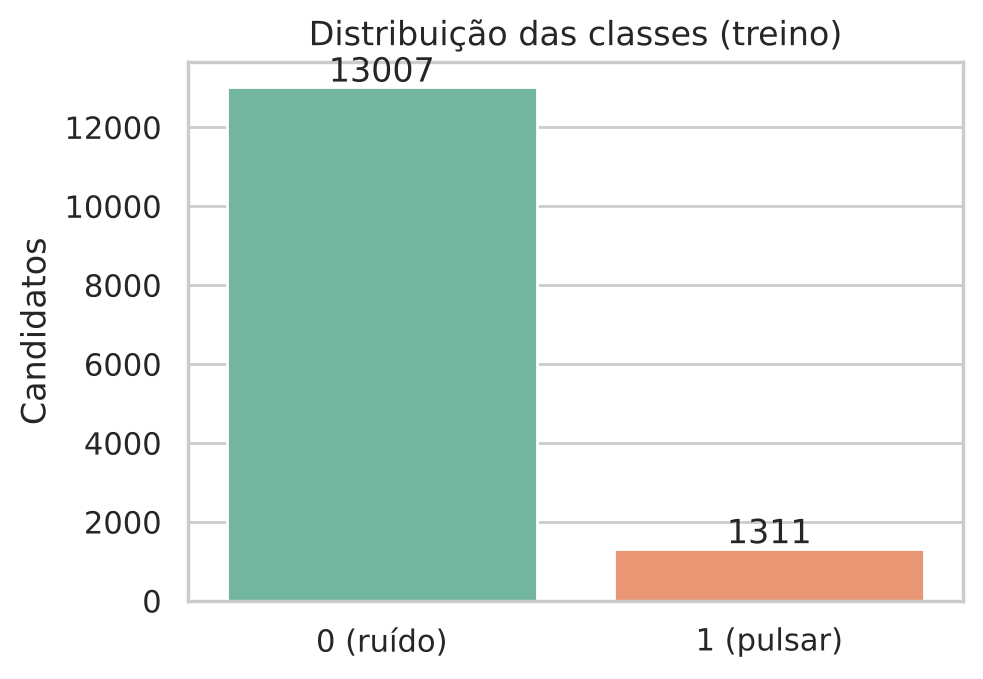

In [7]:
counts = train[target].value_counts().sort_index()
print(counts, "\n", (counts / len(train) * 100).round(2).astype(str) + " %")
print("Acurácia de prever sempre 0:", round(counts[0] / len(train), 4))

fig, ax = plt.subplots(figsize=(5, 3.5))
sns.barplot(x=["0 (ruído)", "1 (pulsar)"], y=counts.values, ax=ax, palette="Set2")
for i, v in enumerate(counts.values): ax.text(i, v + 150, str(v), ha="center")
ax.set_ylabel("Candidatos"); ax.set_title("Distribuição das classes (treino)"); plt.show()

**Resposta.** Há **forte desbalanceamento**: apenas ≈ 9,2% dos candidatos são pulsares (1.311 de 14.318). Um modelo que sempre responde "ruído" acerta ≈ 90,8%, mas não detecta nenhum pulsar. Portanto, **a acurácia é enganosa neste problema**: usaremos PR-AUC, precisão, revocação e F1, e validação cruzada estratificada.

### Pergunta 2. Como se distribuem os atributos?
*Gráfico: histogramas com densidade (forma, assimetria e caudas).*

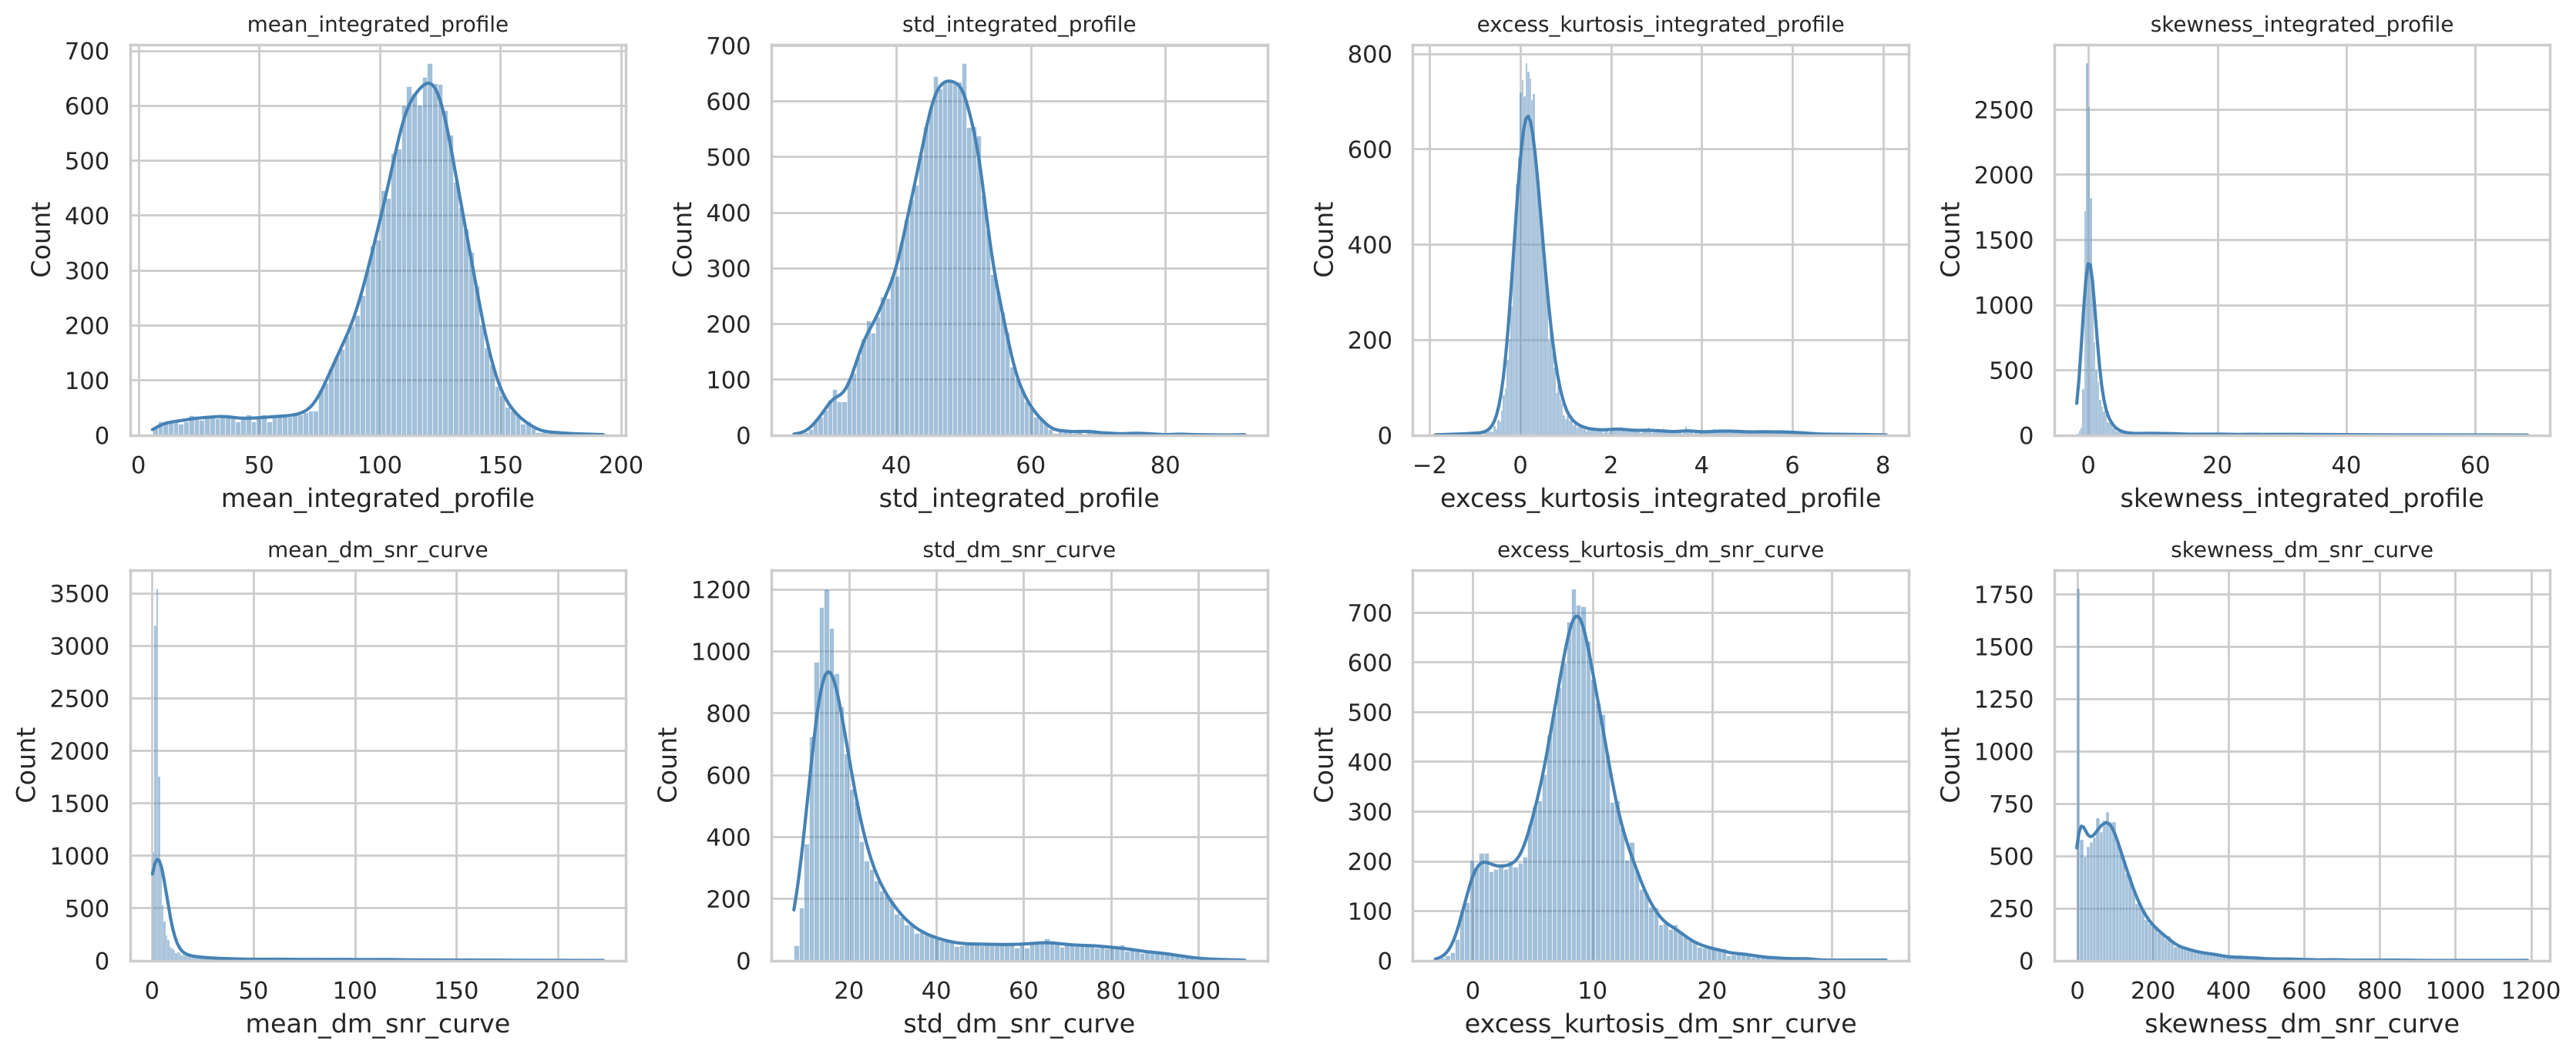

Assimetria (skewness):
mean_integrated_profile              -1.3800
std_integrated_profile                0.0400
excess_kurtosis_integrated_profile    3.6600
skewness_integrated_profile           5.2000
mean_dm_snr_curve                     3.7000
std_dm_snr_curve                      1.9000
excess_kurtosis_dm_snr_curve          0.4500
skewness_dm_snr_curve                 2.7100
dtype: float64


In [8]:
fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for ax, c in zip(axes.ravel(), features):
    sns.histplot(train[c], kde=True, ax=ax, color="steelblue"); ax.set_title(c, fontsize=10)
plt.tight_layout(); plt.show()
print("Assimetria (skewness):"); print(train[features].skew().round(2))

**Resposta.** A maioria dos atributos tem **assimetria forte e caudas longas à direita**: `skewness_integrated_profile` (≈ 5,2), `mean_dm_snr_curve` (≈ 3,7), `excess_kurtosis_integrated_profile` (≈ 3,7), `skewness_dm_snr_curve` (≈ 2,7) e `std_dm_snr_curve` (≈ 1,9). `mean_integrated_profile` é assimétrica à esquerda (≈ −1,4), e `std_integrated_profile` e `excess_kurtosis_dm_snr_curve` são aproximadamente simétricas. Essas caudas pesadas são coerentes com a presença de muitos outliers (seção 1.3) e fazem com que a padronização, por si só, não deixe as distribuições "bem comportadas" para modelos baseados em distância.

### Pergunta 3. Quais atributos mais diferenciam pulsares de ruído?
*Gráfico: barras horizontais da diferença padronizada de médias (d de Cohen).*

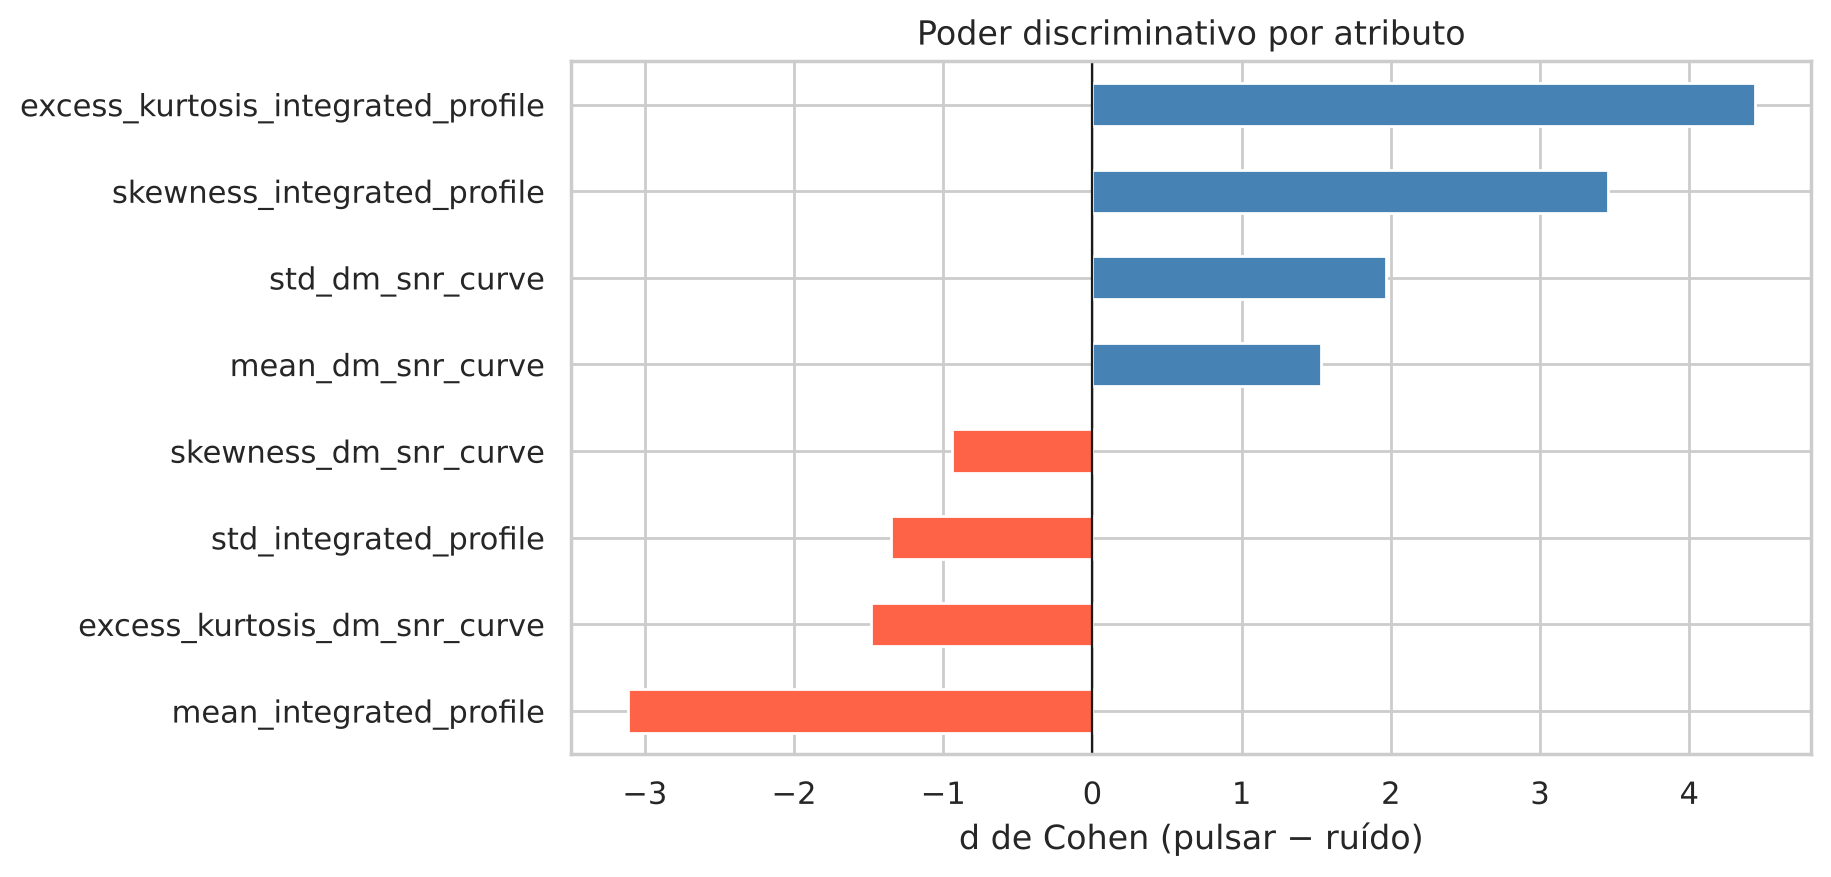

mean_integrated_profile              -3.1100
excess_kurtosis_dm_snr_curve         -1.4800
std_integrated_profile               -1.3500
skewness_dm_snr_curve                -0.9400
mean_dm_snr_curve                     1.5300
std_dm_snr_curve                      1.9700
skewness_integrated_profile           3.4500
excess_kurtosis_integrated_profile    4.4400
dtype: float64

In [9]:
def cohen_d(a, b):
    na, nb = len(a), len(b)
    sp = np.sqrt(((na - 1) * a.var(ddof=1) + (nb - 1) * b.var(ddof=1)) / (na + nb - 2))
    return (a.mean() - b.mean()) / sp

pul, rui = train[train[target] == 1], train[train[target] == 0]
d = pd.Series({c: cohen_d(pul[c], rui[c]) for c in features}).sort_values()

fig, ax = plt.subplots(figsize=(8, 4.5))
d.plot.barh(ax=ax, color=["tomato" if v < 0 else "steelblue" for v in d])
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("d de Cohen (pulsar − ruído)"); ax.set_title("Poder discriminativo por atributo"); plt.show()
d.round(2)

**Resposta.** Os atributos do **perfil integrado** são os mais discriminativos: `excess_kurtosis_integrated_profile` (d ≈ 4,4), `skewness_integrated_profile` (≈ 3,5) e `mean_integrated_profile` (≈ −3,1, pulsares com média menor). Os atributos da **curva DM–SNR** separam menos (|d| entre ≈ 0,9 e 2,0), com destaque para `std_dm_snr_curve`. Como as distribuições são assimétricas, o d de Cohen é uma medida aproximada, mas a ordem de importância é nítida.

### Pergunta 4. Como cada classe se distribui nos atributos mais discriminativos?
*Gráfico: boxplots por classe (mediana, dispersão e outliers lado a lado).*

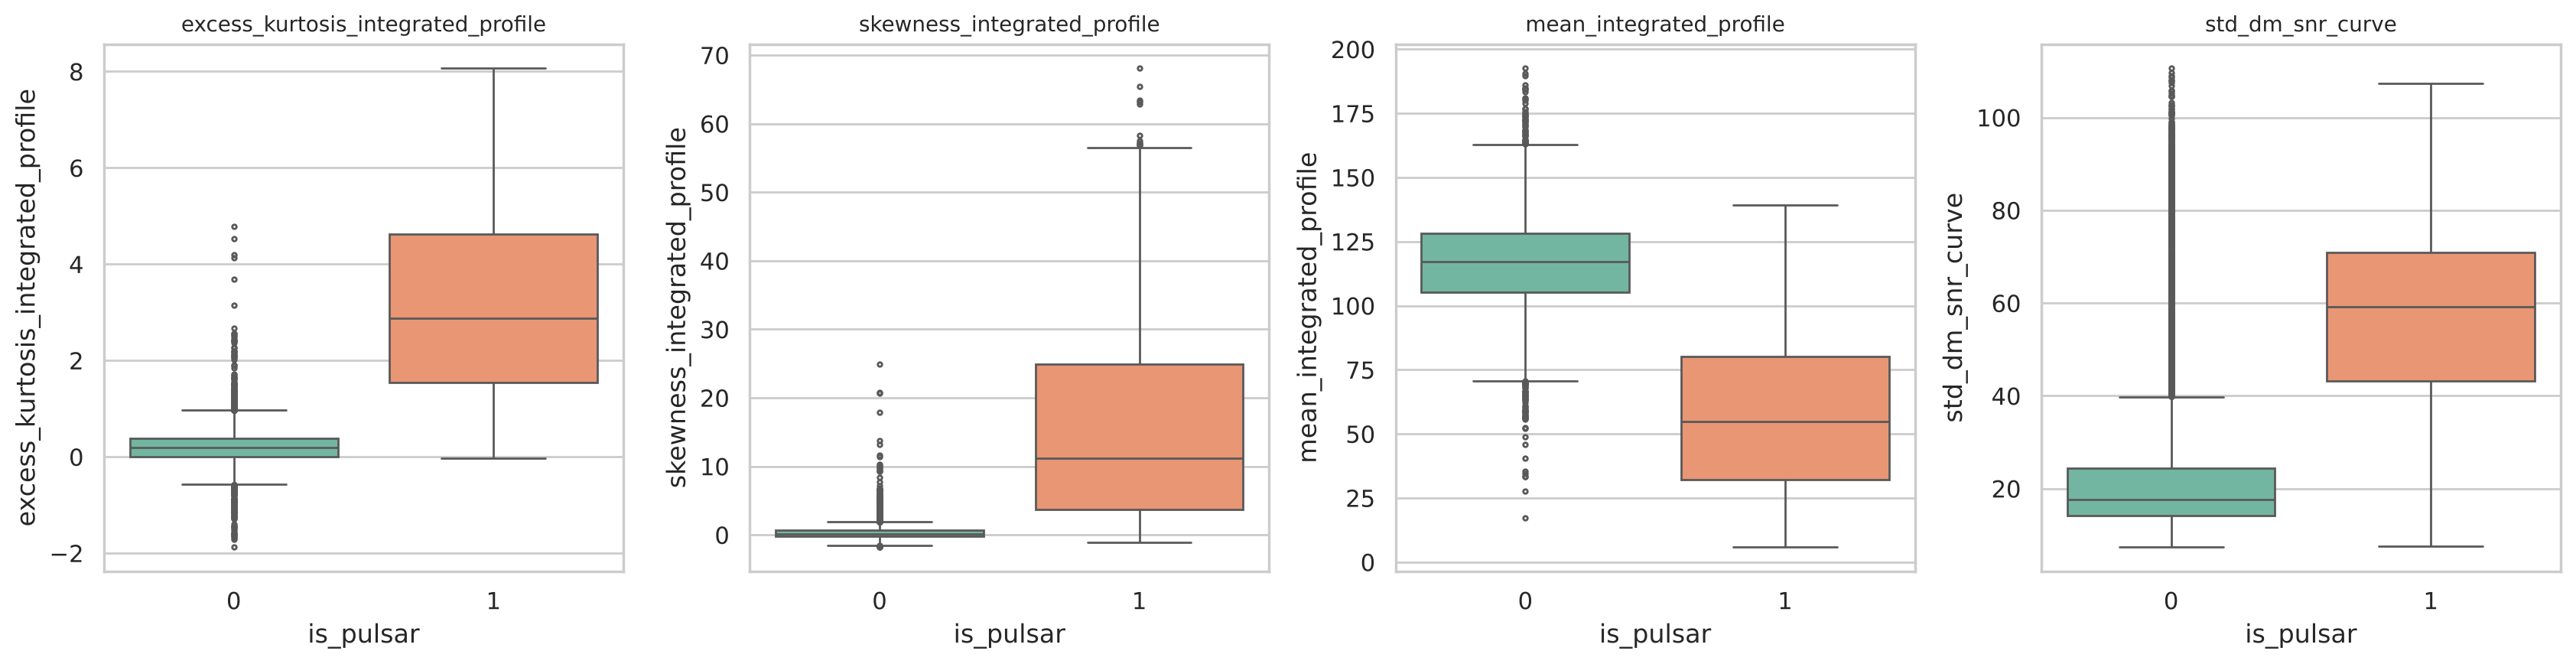

,excess_kurtosis_integrated_profile,skewness_integrated_profile,mean_integrated_profile,std_dm_snr_curve
is_pulsar,,,,
0,0.1900,0.1200,117.3000,17.5800
1,2.8700,11.2400,54.9500,59.2400


In [10]:
top = ["excess_kurtosis_integrated_profile", "skewness_integrated_profile",
       "mean_integrated_profile", "std_dm_snr_curve"]
fig, axes = plt.subplots(1, 4, figsize=(17, 4.5))
for ax, c in zip(axes, top):
    sns.boxplot(data=train, x=target, y=c, palette="Set2", ax=ax, fliersize=2)
    ax.set_title(c, fontsize=10); ax.set_xlabel("is_pulsar")
plt.tight_layout(); plt.show()
train.groupby(target)[top].median().round(2)

**Resposta.** Os boxplots confirmam a separação: o pulsar típico tem **curtose e assimetria do perfil integrado muito maiores** (medianas ≈ 2,9 e ≈ 11,2, contra ≈ 0,2 e ≈ 0,1 no ruído), **média do perfil menor** (≈ 55 contra ≈ 117) e **maior desvio-padrão da curva DM–SNR** (≈ 59 contra ≈ 18). Ainda assim há **sobreposição** entre as caixas e muitos pontos extremos nas duas classes, de modo que nenhum atributo isolado resolve o problema.

### Pergunta 5. Quão correlacionados estão os atributos entre si?
*Gráfico: mapa de calor (todas as correlações par a par de uma vez).*

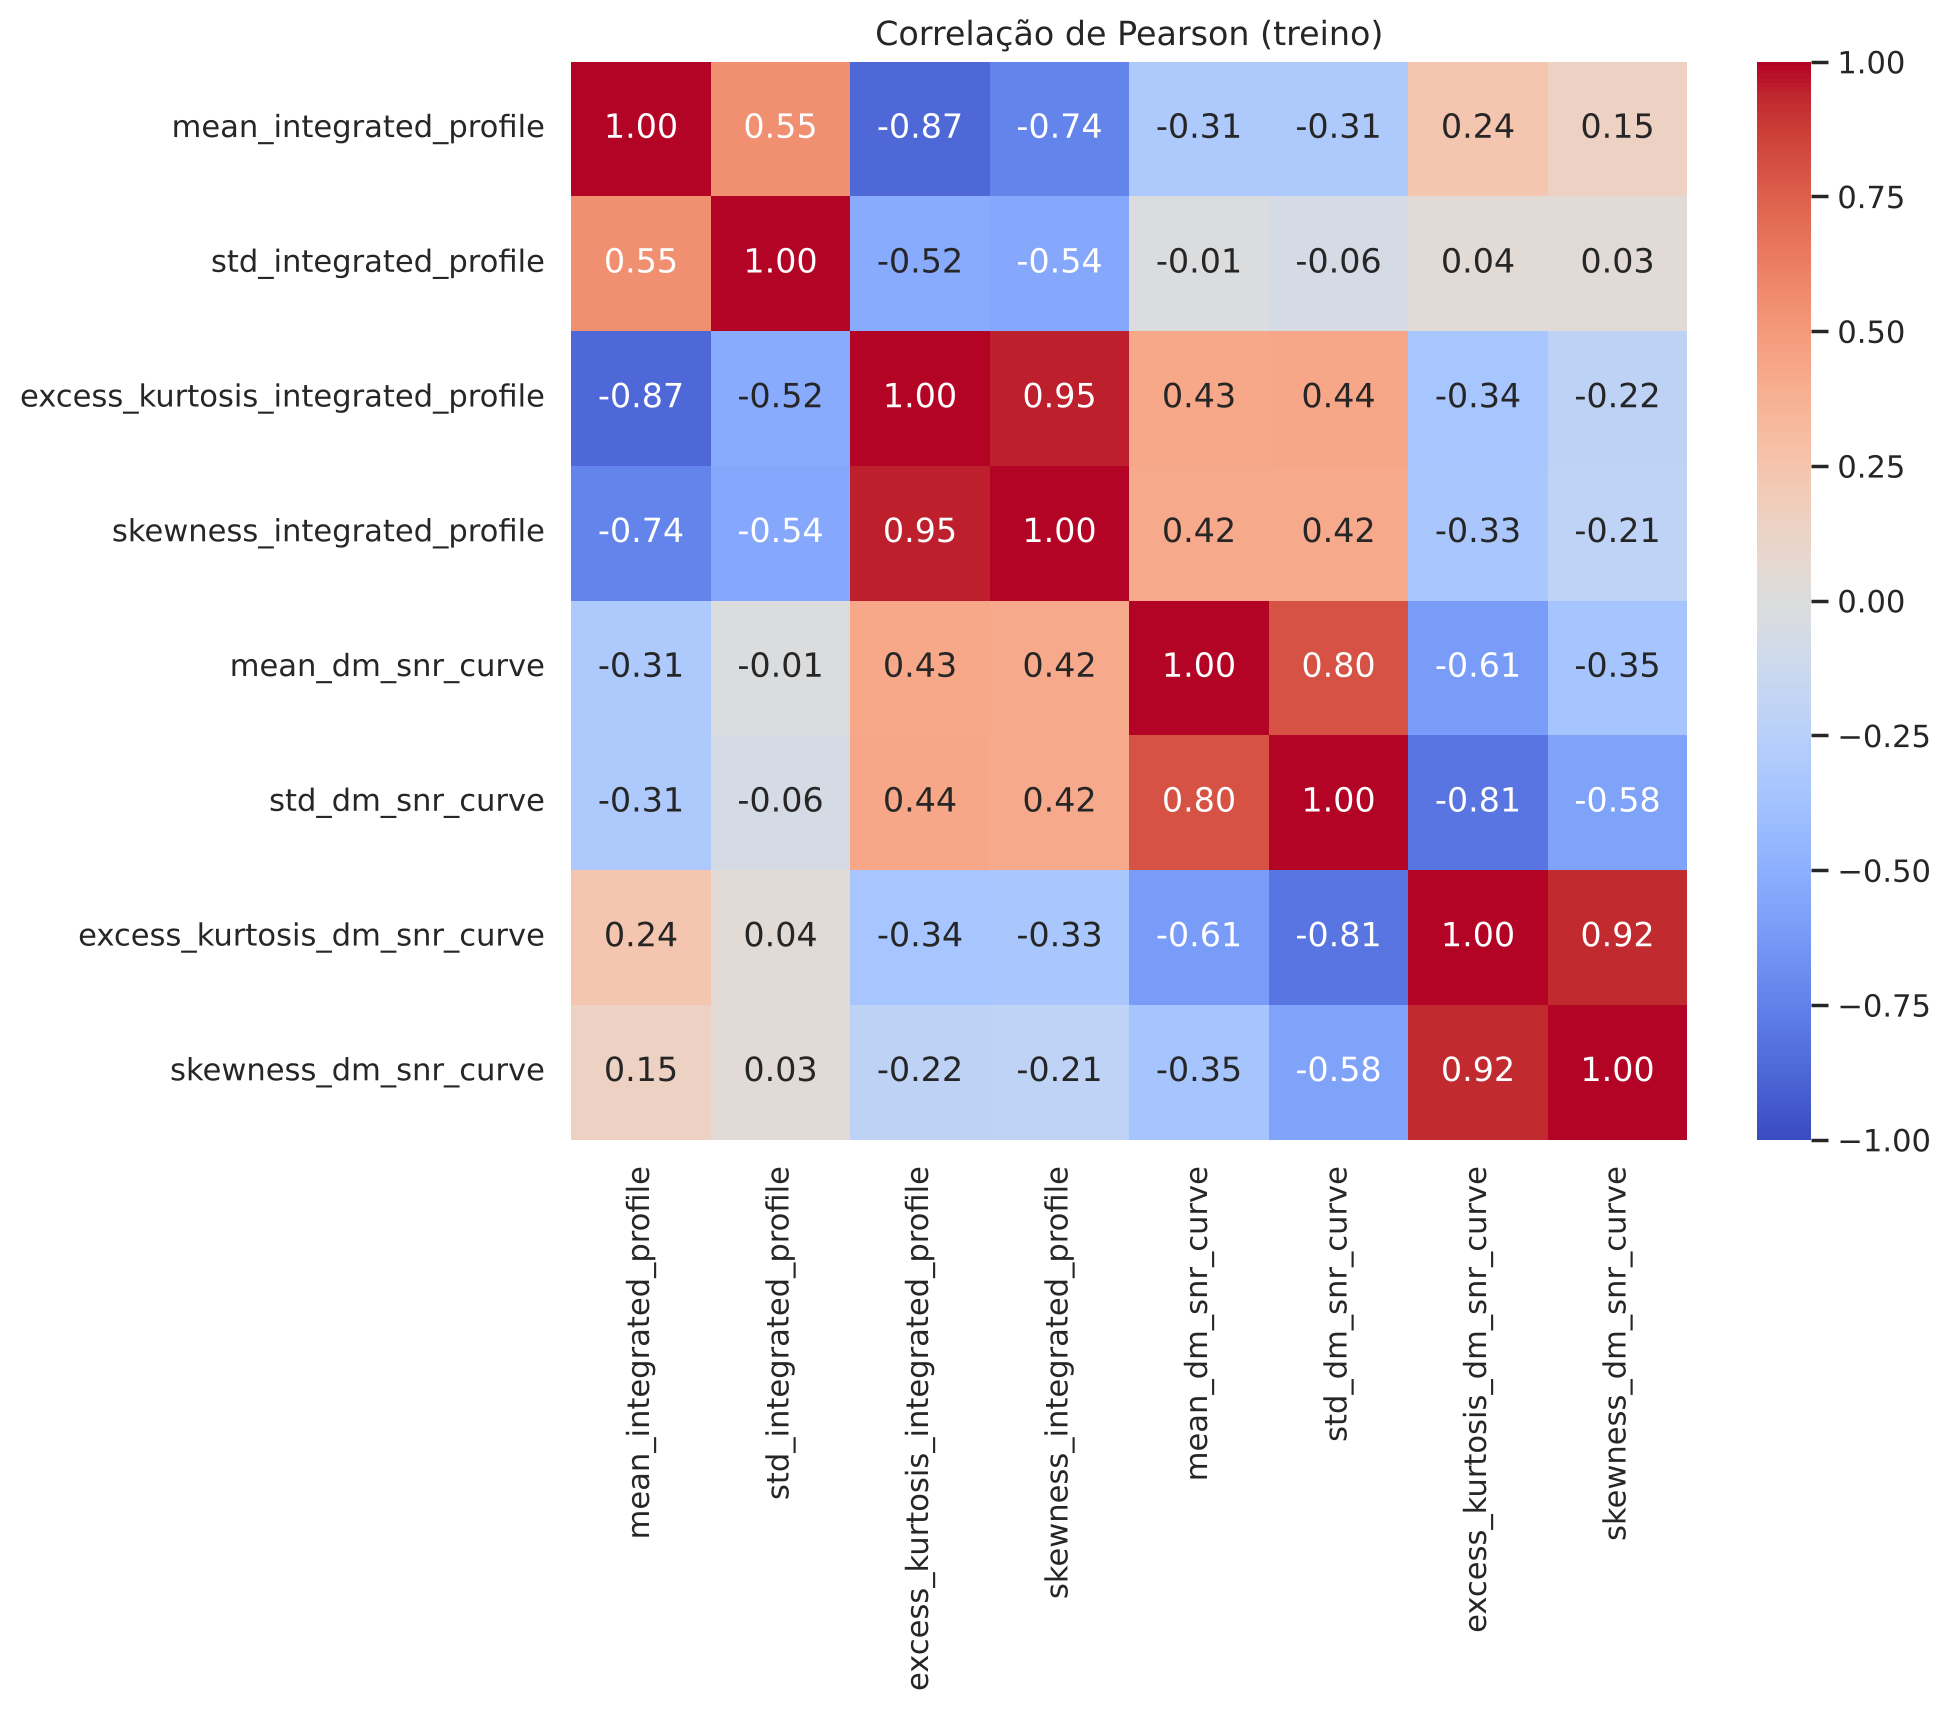

,,corr
excess_kurtosis_integrated_profile,skewness_integrated_profile,0.9464
excess_kurtosis_dm_snr_curve,skewness_dm_snr_curve,0.9248
mean_integrated_profile,excess_kurtosis_integrated_profile,-0.8730
std_dm_snr_curve,excess_kurtosis_dm_snr_curve,-0.8085
mean_dm_snr_curve,std_dm_snr_curve,0.8000
mean_integrated_profile,skewness_integrated_profile,-0.7389


In [11]:
corr = train[features].corr()
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlação de Pearson (treino)"); plt.show()

pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack()
         .rename("corr").to_frame().assign(abs=lambda x: x["corr"].abs()).sort_values("abs", ascending=False))
pairs.head(6)[["corr"]]

**Resposta.** Há **colinearidade forte** dentro de cada grupo de atributos: curtose × assimetria do perfil integrado (≈ 0,95), curtose × assimetria da curva DM–SNR (≈ 0,92), `mean_integrated_profile` × curtose do perfil (≈ −0,87), `std_dm_snr_curve` × curtose da curva DM–SNR (≈ −0,81) e `mean_dm_snr_curve` × `std_dm_snr_curve` (≈ 0,80). Assim, os atributos carregam informação parcialmente redundante. Isso não prejudica árvores nem SVM/KNN de forma grave, mas torna os coeficientes individuais da regressão logística instáveis.

### Pergunta 6. O perfil integrado separa as classes no plano curtose × assimetria?
*Gráfico: dispersão colorida por classe (fronteiras e sobreposição no plano).*

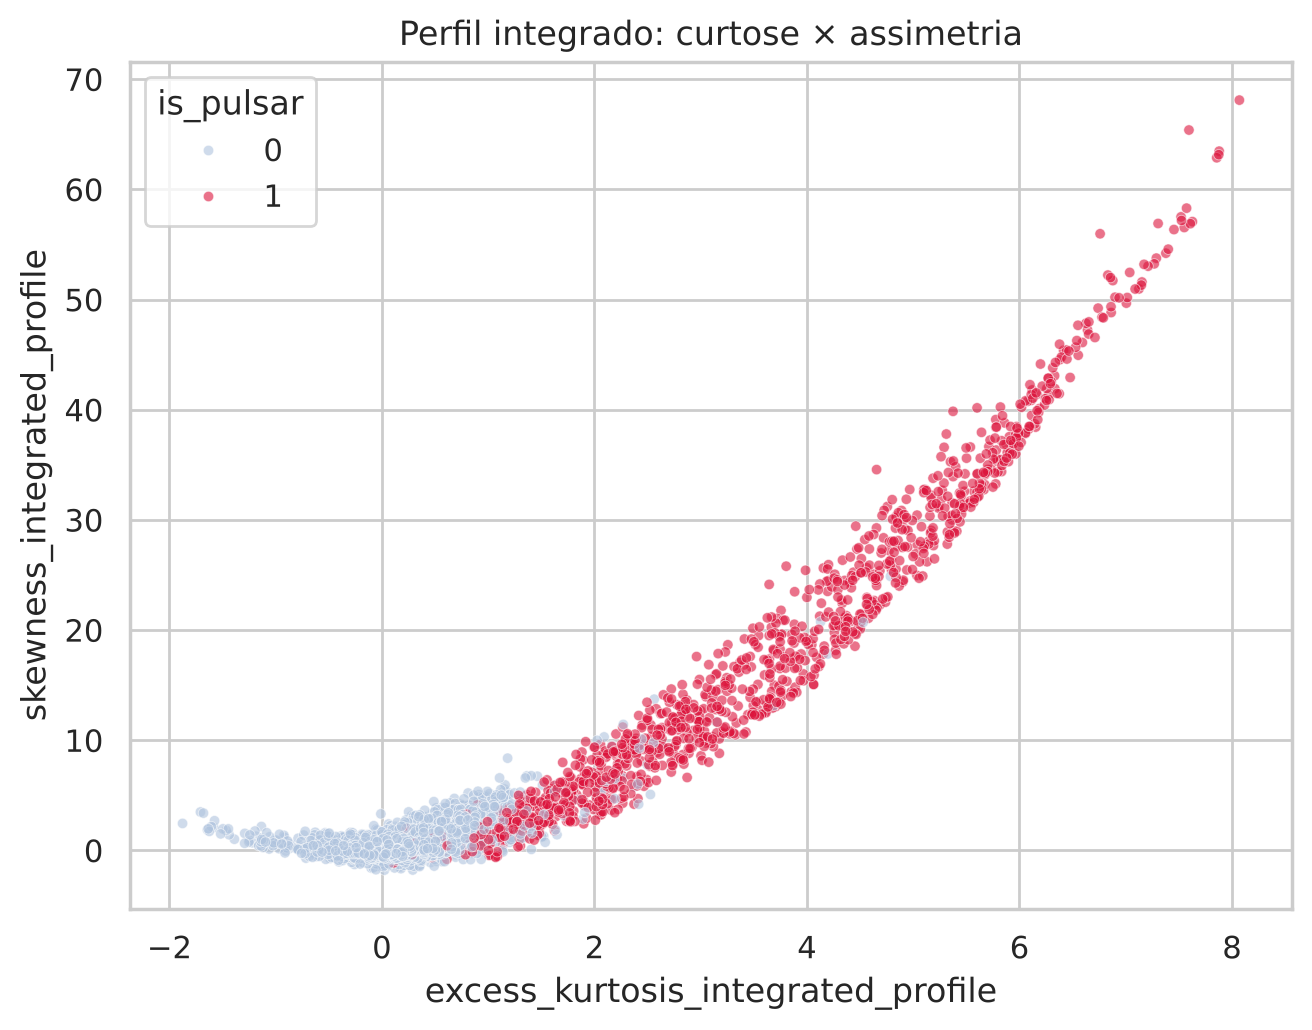

In [12]:
fig, ax = plt.subplots(figsize=(7.5, 5.5))
sns.scatterplot(data=train.sample(frac=1, random_state=SEED), x="excess_kurtosis_integrated_profile",
                y="skewness_integrated_profile", hue=target, palette={0: "lightsteelblue", 1: "crimson"},
                alpha=0.6, s=14, ax=ax)
ax.set_title("Perfil integrado: curtose × assimetria"); plt.show()

**Resposta.** Os pulsares (em vermelho) se concentram na região de **curtose e assimetria elevadas**, enquanto o ruído se aglomera perto de valores baixos nos dois eixos, o que confirma o poder discriminativo visto na pergunta 3. Existe, porém, uma **zona de transição com sobreposição**, onde candidatos das duas classes ficam misturados; é nela que os modelos tendem a errar.

### Pergunta 7. Qual a proporção de pulsares entre os valores extremos (outliers)?
*Gráfico: barras com a fração de pulsares nos outliers de cada atributo, contra a taxa geral.*

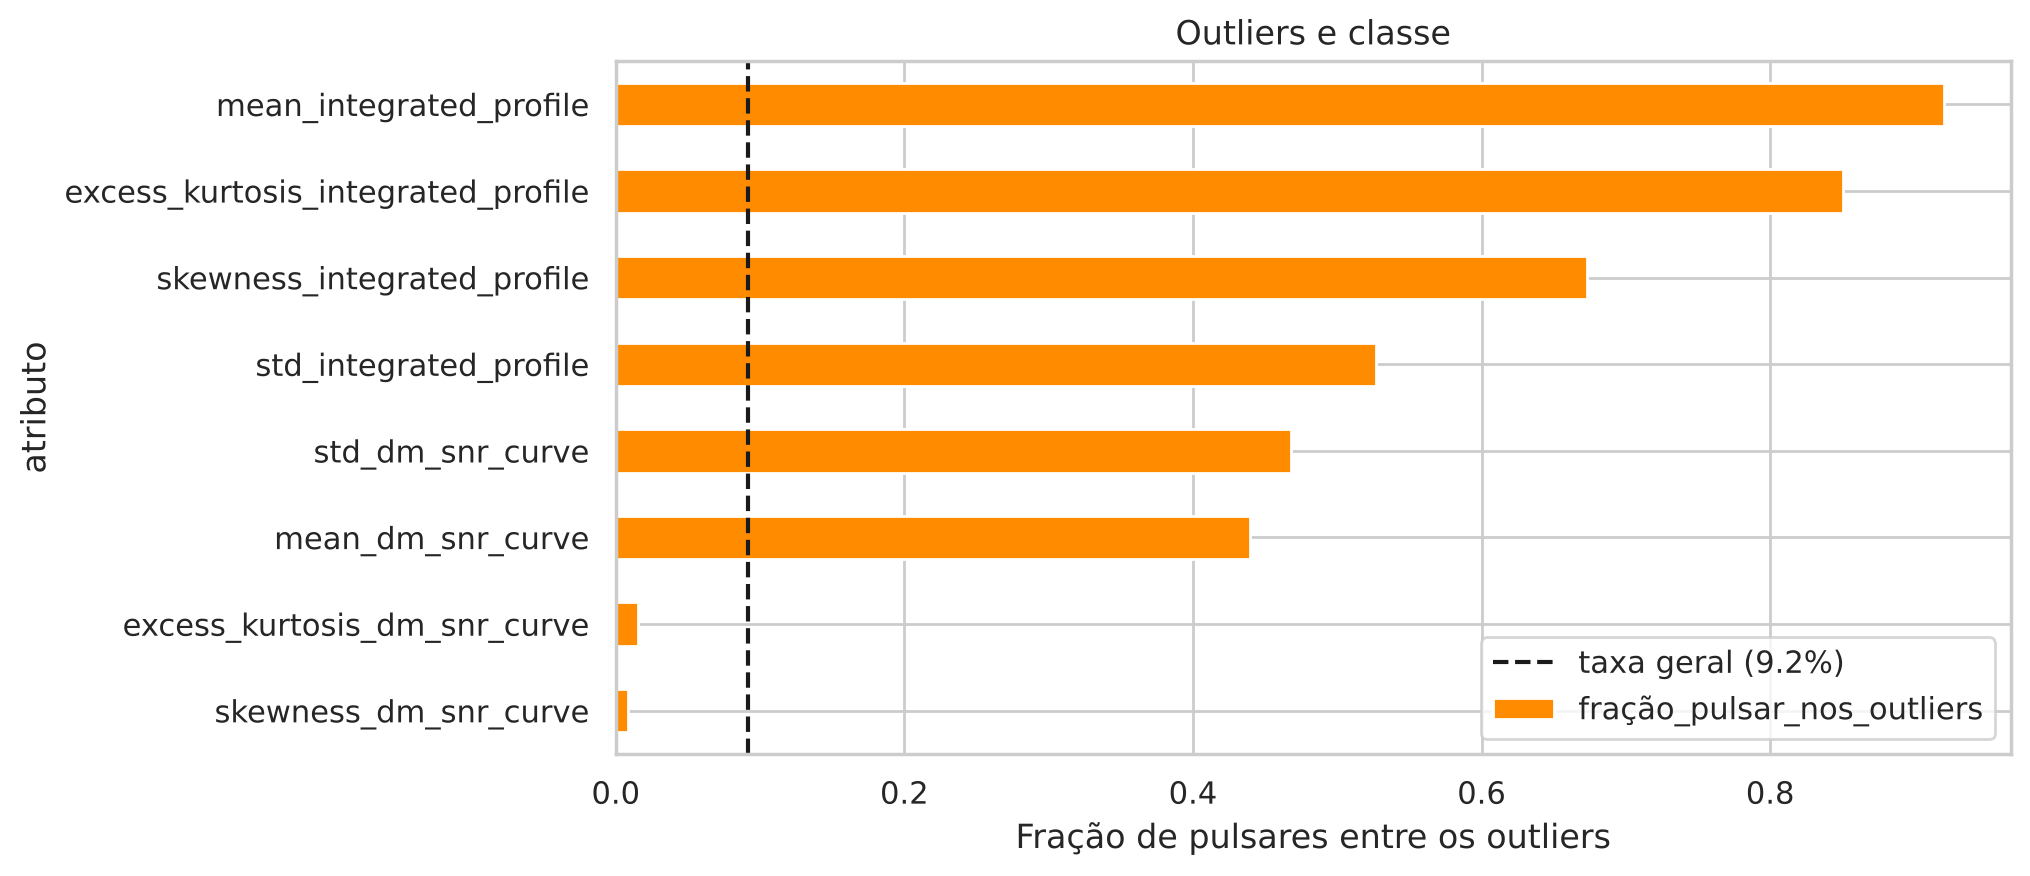

In [13]:
frac = outliers["fração_pulsar_nos_outliers"]
fig, ax = plt.subplots(figsize=(9, 4.5))
frac.sort_values().plot.barh(ax=ax, color="darkorange")
ax.axvline(train[target].mean(), color="k", ls="--", label=f"taxa geral ({train[target].mean():.1%})")
ax.set_xlabel("Fração de pulsares entre os outliers"); ax.legend(); ax.set_title("Outliers e classe"); plt.show()

**Resposta.** Valores extremos **não são ruído de medição**: nos atributos do perfil integrado, a fração de pulsares entre os outliers é muito maior que a taxa geral (≈ 9%) (≈ 92% em `mean_integrated_profile` e ≈ 85% em `excess_kurtosis_integrated_profile`). Já nos outliers de `excess_kurtosis_dm_snr_curve` e `skewness_dm_snr_curve` quase não há pulsares. Isso reforça a decisão de **manter os outliers**, pois eles carregam informação sobre a classe.

### Pergunta 8. A curva DM–SNR separa as classes?
*Gráfico: dispersão (média × desvio-padrão da curva DM–SNR), por classe.*

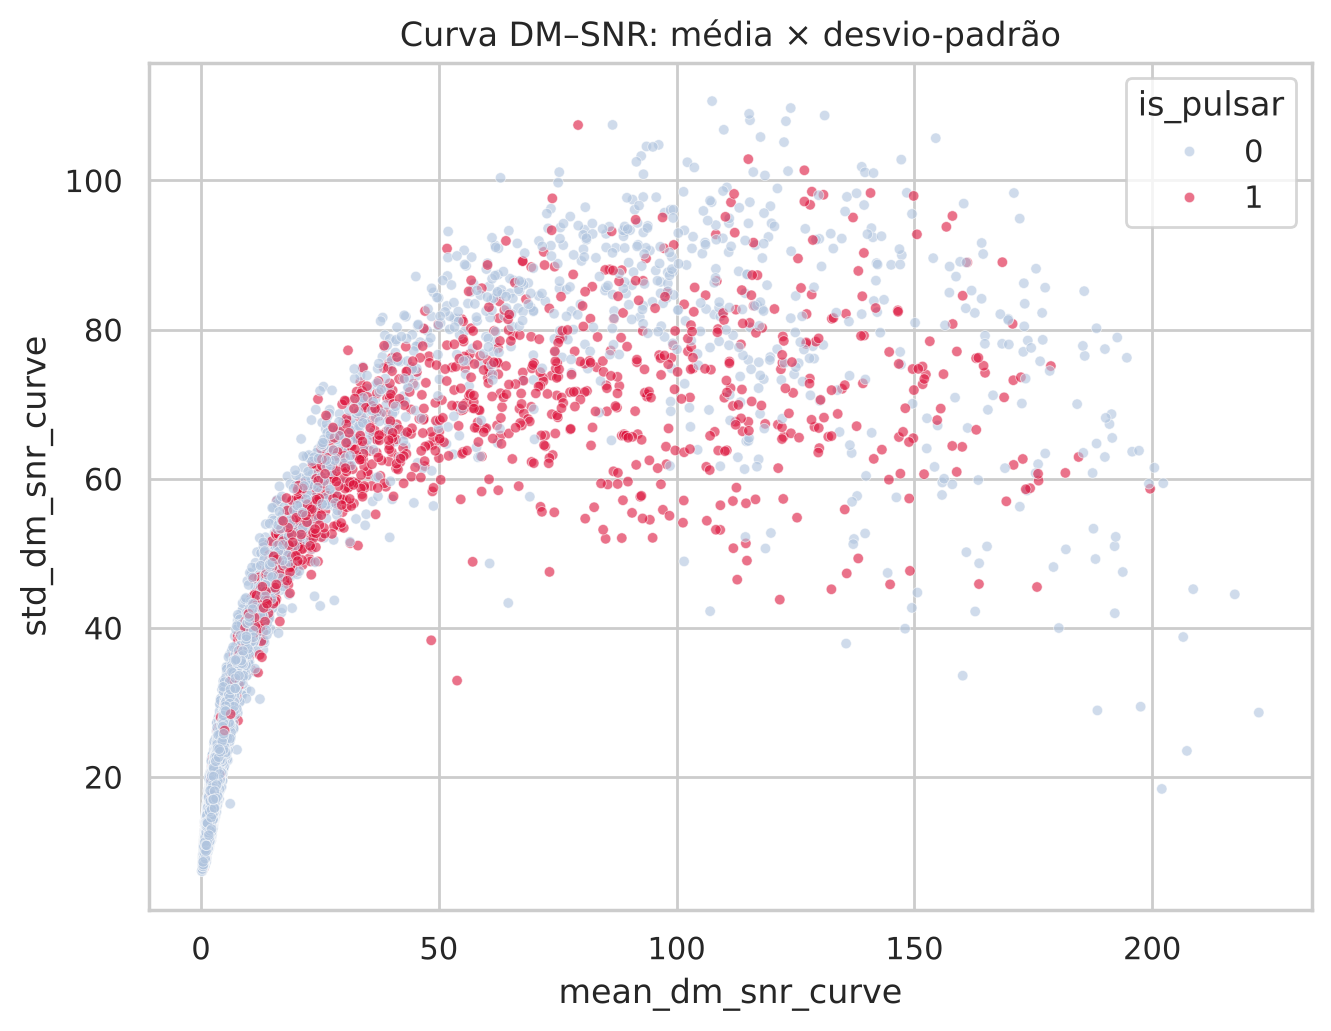

In [14]:
fig, ax = plt.subplots(figsize=(7.5, 5.5))
sns.scatterplot(data=train.sample(frac=1, random_state=SEED), x="mean_dm_snr_curve", y="std_dm_snr_curve",
                hue=target, palette={0: "lightsteelblue", 1: "crimson"}, alpha=0.6, s=14, ax=ax)
ax.set_title("Curva DM–SNR: média × desvio-padrão"); plt.show()

**Resposta.** Na curva DM–SNR os pulsares tendem a ter **média e desvio-padrão maiores**, mas a **sobreposição com o ruído é bem maior** do que no perfil integrado (consistente com os valores de d mais baixos da pergunta 3). A curva DM–SNR ajuda, mas sozinha separa pior as classes.

### Síntese dos achados e limitações

**Achados**
- Dados limpos (sem faltantes, duplicatas ou valores inválidos) e **fortemente desbalanceados** (≈ 9% de pulsares); a acurácia seria enganosa.
- Os atributos do **perfil integrado** (curtose, assimetria e média) são os mais discriminativos; a curva DM–SNR contribui, mas separa menos.
- Distribuições **assimétricas, com caudas longas**, e muitos outliers que **carregam informação da classe**, por isso foram mantidos.
- **Colinearidade** forte entre atributos do mesmo sinal (curtose × assimetria).
- As classes são bem separáveis no geral, com **zona de sobreposição** que concentra os erros.

**Limitações da base**
- As variáveis são **estatísticas resumidas**, não os sinais brutos nem imagens: não dá para investigar visualmente os erros nem usar modelos sobre o sinal.
- Não há posição no céu nem propriedades físicas: o modelo apenas tria candidatos, não explica o pulsar.
- Só ≈ 1.300 exemplos positivos no treino (328 no teste), o que torna as métricas da classe rara **sensíveis a poucos casos**.

## 3. Modelagem

### 3.1 Tarefa e alvo

**Classificação binária** de `is_pulsar` (1 = pulsar real, classe positiva e minoritária; 0 = interferência/ruído).

### 3.2 Separação treino/teste e prevenção de vazamento

A separação **já é fornecida** (estratificada) e foi feita antes de qualquer transformação. Cuidados contra vazamento:

1. O teste não foi usado na EDA nem nas decisões de preparação.
2. A padronização fica dentro de um `Pipeline`, ajustada apenas nas dobras de treino de cada rodada da validação cruzada.
3. A busca de hiperparâmetros e a escolha do limiar de decisão usam apenas validação cruzada no treino.
4. O teste é usado **uma única vez**, ao final, com os modelos e o limiar já definidos.

In [15]:
X_train, y_train = train[features], train[target]
X_test, y_test = test[features], test[target]
print("Treino:", X_train.shape, "| positivos:", round(y_train.mean(), 4))
print("Teste: ", X_test.shape, "| positivos:", round(y_test.mean(), 4))

Treino: (14318, 8) | positivos: 0.0916
Teste:  (3580, 8) | positivos: 0.0916


### 3.3 Transformações, modelos e validação

- **Padronização** (`StandardScaler`): Regressão Logística, KNN e SVM (sensíveis à escala). Modelos de árvores dispensam.
- **Encoding:** não há categóricos (o alvo já é 0/1).
- **Balanceamento:** em vez de reamostrar (o que alteraria o conjunto de treino), usamos **pesos de classe** (`class_weight="balanced"`) onde o modelo suporta. O KNN não tem esse recurso e é usado sem ajuste.
- **Seleção de atributos:** mantidos os 8 atributos; a colinearidade é tolerada pelos modelos usados.
- **Validação:** `StratifiedKFold`, 5 dobras, `random_state=42`.

**Modelos**
1. **Baseline:** `DummyClassifier` (sempre classe 0).
2. **Regressão Logística:** modelo linear simples e interpretável.
3. **KNN.**
4. **SVM com kernel RBF.**
5. **Random Forest.**
6. **Gradient Boosting** (`HistGradientBoostingClassifier`).

**Métricas.** A acurácia engana neste problema (prever sempre 0 já dá ≈ 90,8%). Usamos:
- **PR-AUC** (precisão média): a métrica principal, pois avalia o ranqueamento da classe rara sem ser inflada pelos negativos. É também a métrica usada na busca de hiperparâmetros;
- **Precisão, revocação e F1** da classe pulsar: um falso negativo deixa um pulsar real de fora da inspeção; um falso positivo aumenta o trabalho de revisão;
- **ROC-AUC**, como visão complementar.

### 3.4 Técnica extra: ajuste do limiar de decisão

O limiar padrão (0,5 na probabilidade) não é necessariamente o melhor com classes desbalanceadas. Além do desempenho no limiar padrão, avaliamos cada modelo com um **limiar ajustado**, escolhido para maximizar o F1 sobre **predições fora da amostra (cross_val_predict) no treino**, e então aplicado ao teste. O teste não participa da escolha. Isso se apoia na curva precisão × revocação, assunto que vai além do que foi trabalhado em sala.

In [16]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

models = {
    "Baseline (Dummy)": (Pipeline([("clf", DummyClassifier(strategy="most_frequent"))]), {}),
    "Regressão Logística": (
        Pipeline([("sc", StandardScaler()), ("clf", LogisticRegression(class_weight="balanced", max_iter=3000, random_state=SEED))]),
        {"clf__C": [0.01, 0.1, 1, 10, 100]}),
    "KNN": (
        Pipeline([("sc", StandardScaler()), ("clf", KNeighborsClassifier(n_jobs=-1))]),
        {"clf__n_neighbors": [5, 11, 21], "clf__weights": ["uniform", "distance"]}),
    "SVM (RBF)": (
        Pipeline([("sc", StandardScaler()), ("clf", SVC(kernel="rbf", class_weight="balanced"))]),
        {"clf__C": [1, 10], "clf__gamma": ["scale"]}),
    "Random Forest": (
        Pipeline([("clf", RandomForestClassifier(class_weight="balanced_subsample", random_state=SEED, n_jobs=-1))]),
        {"clf__n_estimators": [200], "clf__max_depth": [None, 8], "clf__min_samples_leaf": [1, 5]}),
    "Gradient Boosting": (
        Pipeline([("clf", HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED))]),
        {"clf__learning_rate": [0.05, 0.1], "clf__max_leaf_nodes": [15, 31]}),
}

def get_scores(est, X):
    """Pontuação contínua da classe positiva (probabilidade ou margem do SVM)."""
    return est.predict_proba(X)[:, 1] if hasattr(est, "predict_proba") else est.decision_function(X)

### 3.5 Busca de hiperparâmetros

Busca em grade (`GridSearchCV`) com as mesmas 5 dobras estratificadas, otimizando a **PR-AUC (`average_precision`)**, apenas sobre o treino.

In [17]:
fitted, best_params, cv_rows = {}, {}, []
for name, (pipe, grid) in models.items():
    if grid:
        gs = GridSearchCV(pipe, grid, scoring="average_precision", cv=cv, n_jobs=-1).fit(X_train, y_train)
        est, best_params[name] = gs.best_estimator_, gs.best_params_
    else:
        est, best_params[name] = pipe.fit(X_train, y_train), {}
    res = cross_validate(est, X_train, y_train, cv=cv, n_jobs=-1,
                         scoring=["average_precision", "roc_auc", "f1", "recall", "precision"])
    cv_rows.append({"modelo": name, "PR-AUC_cv": res["test_average_precision"].mean(),
                    "PR-AUC_std": res["test_average_precision"].std(),
                    "ROC-AUC_cv": res["test_roc_auc"].mean(), "F1_cv": res["test_f1"].mean(),
                    "recall_cv": res["test_recall"].mean(), "precisão_cv": res["test_precision"].mean()})
    fitted[name] = est

pd.Series({k: (str(v) if v else "—") for k, v in best_params.items()}, name="melhores hiperparâmetros").to_frame()

,melhores hiperparâmetros
Baseline (Dummy),—
Regressão Logística,{'clf__C': 0.1}
KNN,"{'clf__n_neighbors': 21, 'clf__weights': 'dist..."
SVM (RBF),"{'clf__C': 1, 'clf__gamma': 'scale'}"
Random Forest,"{'clf__max_depth': 8, 'clf__min_samples_leaf':..."
Gradient Boosting,"{'clf__learning_rate': 0.1, 'clf__max_leaf_nod..."


In [18]:
cv_table = pd.DataFrame(cv_rows).set_index("modelo")
cv_table

,PR-AUC_cv,PR-AUC_std,ROC-AUC_cv,F1_cv,recall_cv,precisão_cv
modelo,,,,,,
Baseline (Dummy),0.0916,0.0001,0.5000,0.0000,0.0000,0.0000
Regressão Logística,0.9240,0.0133,0.9760,0.8480,0.9070,0.7971
KNN,0.9012,0.0150,0.9590,0.8708,0.8101,0.9427
SVM (RBF),0.8737,0.0134,0.9744,0.8618,0.9131,0.8167
Random Forest,0.9297,0.0129,0.9780,0.8691,0.8932,0.8472
Gradient Boosting,0.9300,0.0131,0.9796,0.8483,0.9108,0.7943


### 3.6 Escolha do limiar (somente com dados de treino)

In [19]:
thresholds = {}
for name, est in fitted.items():
    if name.startswith("Baseline"):
        continue
    method = "predict_proba" if hasattr(est, "predict_proba") else "decision_function"
    oof = cross_val_predict(est, X_train, y_train, cv=cv, method=method, n_jobs=-1)
    oof = oof[:, 1] if oof.ndim == 2 else oof
    p, r, th = precision_recall_curve(y_train, oof)
    f1s = 2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-12)
    thresholds[name] = th[np.argmax(f1s)]

pd.Series(thresholds, name="limiar que maximiza o F1 (OOF no treino)").to_frame()

,limiar que maximiza o F1 (OOF no treino)
Regressão Logística,0.7409
KNN,0.3940
SVM (RBF),0.7361
Random Forest,0.6917
Gradient Boosting,0.8597


## 4. Resultados

Avaliação final no conjunto de **teste**, usado uma única vez.

In [20]:
def metrics(y_true, y_pred, scores):
    return {"acurácia": accuracy_score(y_true, y_pred),
            "precisão": precision_score(y_true, y_pred, zero_division=0),
            "recall": recall_score(y_true, y_pred),
            "F1": f1_score(y_true, y_pred),
            "PR-AUC": average_precision_score(y_true, scores),
            "ROC-AUC": roc_auc_score(y_true, scores)}

rows, rows_tuned, scores_test, pred_tuned = [], [], {}, {}
for name, est in fitted.items():
    s = get_scores(est, X_test); scores_test[name] = s
    rows.append({"modelo": name, **metrics(y_test, est.predict(X_test), s)})
    if name in thresholds:
        pred_tuned[name] = (s >= thresholds[name]).astype(int)
        rows_tuned.append({"modelo": name, **metrics(y_test, pred_tuned[name], s)})

res_default = pd.DataFrame(rows).set_index("modelo")
res_tuned = pd.DataFrame(rows_tuned).set_index("modelo")
print("Limiar padrão:"); display(res_default.sort_values("PR-AUC", ascending=False))
print("Limiar ajustado (escolhido no treino):"); display(res_tuned.sort_values("PR-AUC", ascending=False))

Limiar padrão:


,acurácia,precisão,recall,F1,PR-AUC,ROC-AUC
modelo,,,,,,
Regressão Logística,0.9707,0.7942,0.9177,0.8515,0.9317,0.9723
Random Forest,0.9757,0.8453,0.8994,0.8715,0.9310,0.9772
Gradient Boosting,0.9687,0.7857,0.9055,0.8414,0.9293,0.9731
KNN,0.9818,0.9550,0.8415,0.8947,0.9140,0.9589
SVM (RBF),0.9718,0.8043,0.9146,0.8559,0.8468,0.9661
Baseline (Dummy),0.9084,0.0000,0.0000,0.0000,0.0916,0.5000


Limiar ajustado (escolhido no treino):


,acurácia,precisão,recall,F1,PR-AUC,ROC-AUC
modelo,,,,,,
Regressão Logística,0.9802,0.8954,0.8872,0.8913,0.9317,0.9723
Random Forest,0.9793,0.8920,0.8811,0.8865,0.9310,0.9772
Gradient Boosting,0.9821,0.9286,0.8720,0.8994,0.9293,0.9731
KNN,0.9810,0.9248,0.8628,0.8927,0.9140,0.9589
SVM (RBF),0.9791,0.8941,0.8750,0.8844,0.8468,0.9661


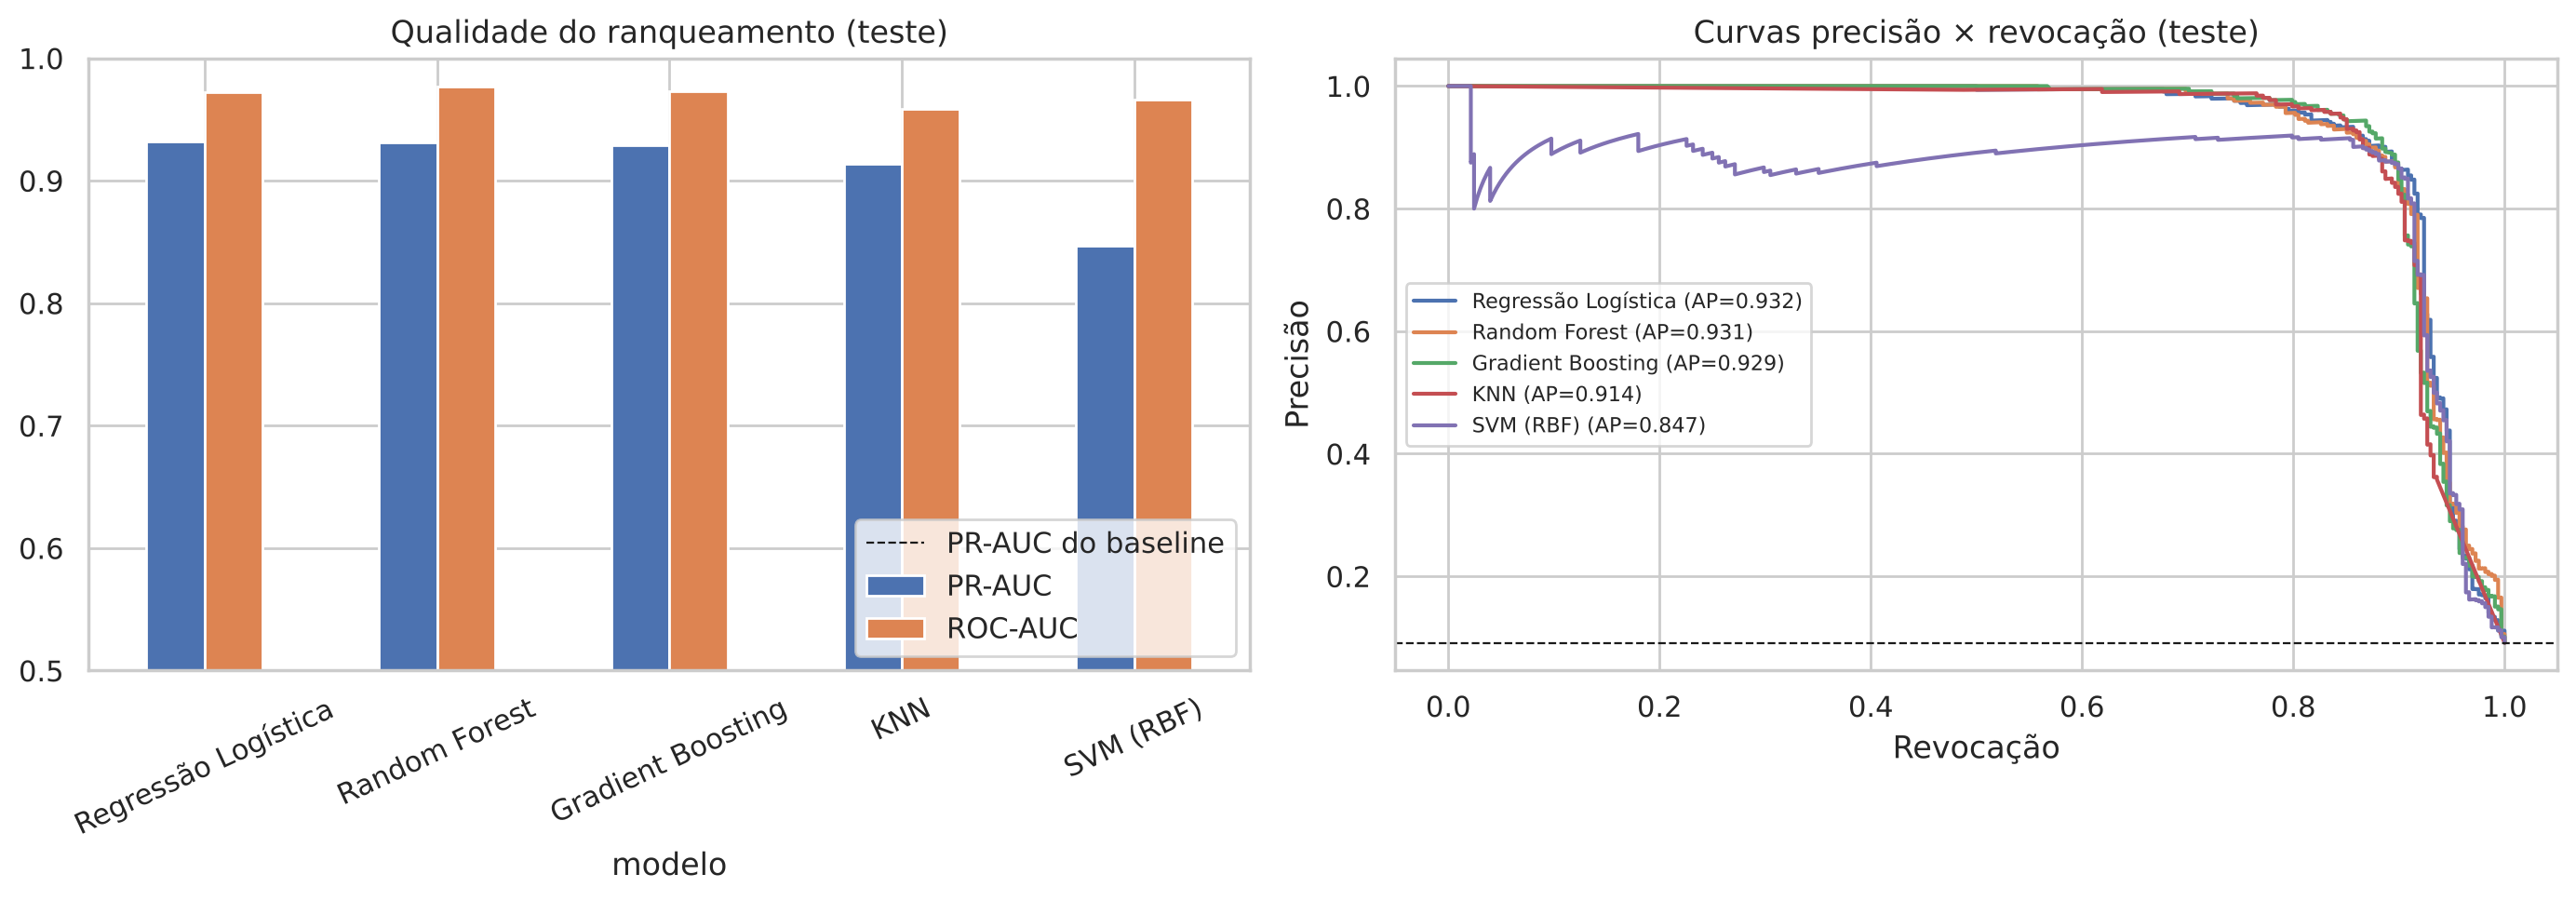

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
order = res_default.drop("Baseline (Dummy)").sort_values("PR-AUC", ascending=False).index
res_default.loc[order, ["PR-AUC", "ROC-AUC"]].plot.bar(ax=axes[0], rot=25)
axes[0].axhline(y_test.mean(), color="k", ls="--", lw=0.8, label="PR-AUC do baseline")
axes[0].set_ylim(0.5, 1.0); axes[0].set_title("Qualidade do ranqueamento (teste)"); axes[0].legend(loc="lower right")

for name in order:
    p, r, _ = precision_recall_curve(y_test, scores_test[name])
    axes[1].plot(r, p, label=f"{name} (AP={average_precision_score(y_test, scores_test[name]):.3f})")
axes[1].axhline(y_test.mean(), color="k", ls="--", lw=0.8)
axes[1].set_xlabel("Revocação"); axes[1].set_ylabel("Precisão"); axes[1].set_title("Curvas precisão × revocação (teste)")
axes[1].legend(fontsize=8); plt.tight_layout(); plt.show()

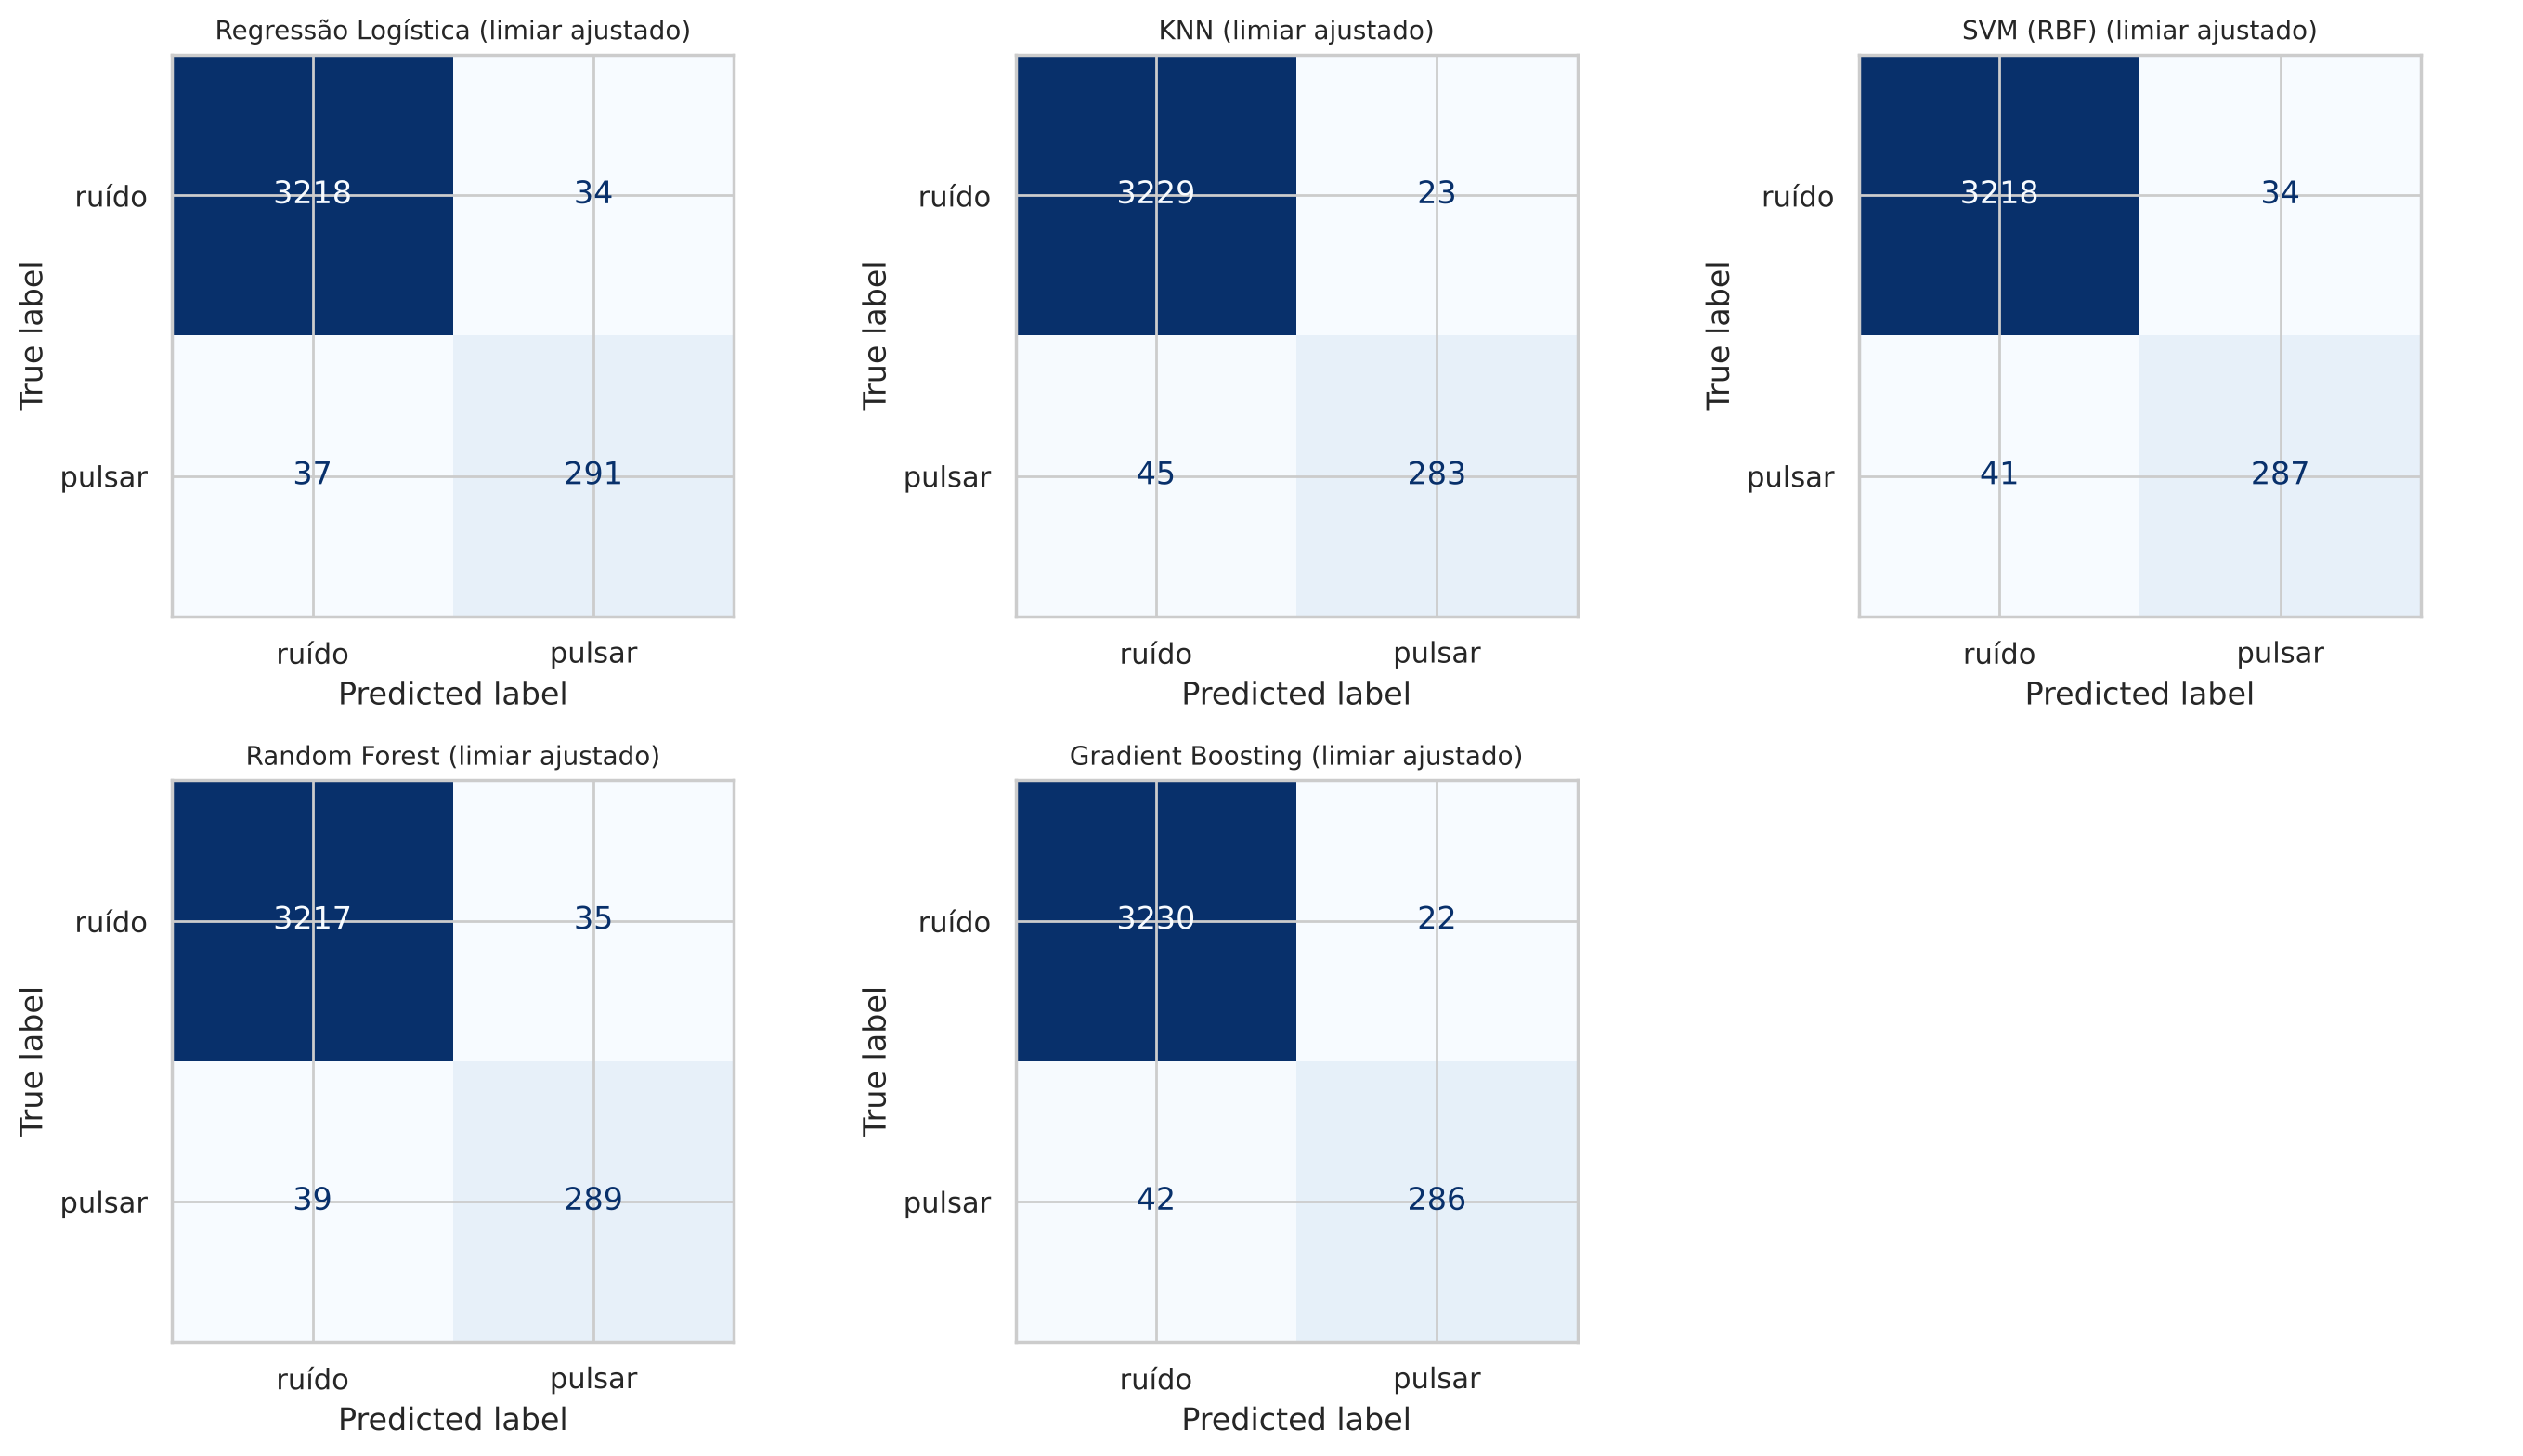

In [22]:
names = list(pred_tuned)
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, name in zip(axes.ravel(), names):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred_tuned[name]),
                           display_labels=["ruído", "pulsar"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{name} (limiar ajustado)", fontsize=10)
for ax in axes.ravel()[len(names):]: ax.axis("off")
plt.tight_layout(); plt.show()

In [23]:
best_name = res_tuned["F1"].idxmax()
print("Melhor modelo no teste (F1, limiar ajustado):", best_name, "\n")
print(classification_report(y_test, pred_tuned[best_name], target_names=["ruído", "pulsar"], digits=3))

Melhor modelo no teste (F1, limiar ajustado): Gradient Boosting 

              precision    recall  f1-score   support

       ruído      0.987     0.993     0.990      3252
      pulsar      0.929     0.872     0.899       328

    accuracy                          0.982      3580
   macro avg      0.958     0.933     0.945      3580
weighted avg      0.982     0.982     0.982      3580



### Atributos mais relevantes

In [24]:
imp = pd.DataFrame(index=features)
imp["coef. logística (padronizado)"] = fitted["Regressão Logística"].named_steps["clf"].coef_[0]
imp["importância RF"] = fitted["Random Forest"].named_steps["clf"].feature_importances_
imp.sort_values("importância RF", ascending=False)

,coef. logística (padronizado),importância RF
excess_kurtosis_integrated_profile,4.4162,0.3464
mean_integrated_profile,0.0673,0.1811
skewness_integrated_profile,-0.5761,0.1492
std_dm_snr_curve,1.0306,0.1246
mean_dm_snr_curve,-0.6685,0.0729
skewness_dm_snr_curve,-0.4210,0.0701
excess_kurtosis_dm_snr_curve,0.1333,0.0321
std_integrated_profile,0.2246,0.0236


### Interpretação no contexto do problema

- **Todos os modelos superam o baseline com folga.** O baseline tem acurácia de ≈ 90,8%, mas **revocação zero**: nenhum pulsar é encontrado. Todos os demais alcançam PR-AUC bem acima do baseline (≈ 0,09), o que confirma que os atributos carregam sinal forte.
- **Os melhores modelos estão praticamente empatados.** Regressão Logística, Random Forest e Gradient Boosting têm PR-AUC ≈ 0,93 no teste e na validação cruzada, e a diferença entre eles (< 0,005) é bem menor que o desvio-padrão entre dobras (≈ 0,013). O SVM (RBF) teve a menor PR-AUC (≈ 0,85); isso pode refletir a grade pequena usada e o fato de a pontuação do SVM ser uma margem, não uma probabilidade, e não deve ser tomado como limite do método. A **regressão logística, o modelo mais simples, ficou entre os melhores**, o que indica que o problema é, em boa parte, quase linearmente separável nos atributos do perfil integrado.
- **Efeito do limiar.** No limiar padrão, os modelos com pesos de classe privilegiam a revocação (≈ 0,90–0,92) com precisão menor (≈ 0,79–0,85), isto é, mais falsos alarmes; o KNN faz o contrário (precisão ≈ 0,96, revocação ≈ 0,84). Com o **limiar ajustado no treino**, os modelos convergem para um equilíbrio (precisão e revocação ≈ 0,87–0,93), e o F1 no teste fica entre ≈ 0,88 e ≈ 0,90. O Gradient Boosting tem o maior F1 (≈ 0,90), mas as diferenças entre modelos são de poucos casos entre 328 pulsares e **não são conclusivas**.
- **Leitura prática** (Gradient Boosting, limiar ajustado): de 328 pulsares, ≈ 87% são encontrados (cerca de 42 ficam de fora) e ≈ 93% dos candidatos sinalizados são de fato pulsares (cerca de 22 falsos alarmes). Se o custo de **perder um pulsar real** for maior que o de revisar um falso alarme, vale baixar o limiar e aceitar mais falsos positivos; se a capacidade de revisão for limitada, vale o contrário.
- **Atributos relevantes.** Tanto a regressão logística quanto o Random Forest apontam `excess_kurtosis_integrated_profile` como o atributo mais importante, seguido de `mean_integrated_profile` e `skewness_integrated_profile`, de acordo com a EDA. Por causa da colinearidade, os coeficientes individuais da regressão logística devem ser lidos com cautela.

### Limitações e possíveis melhorias

- **Poucos positivos:** com 328 pulsares no teste, diferenças de ~1 p.p. entre modelos são ruído; intervalos de confiança (bootstrap) ou validação cruzada repetida dariam mais segurança.
- **Escolha do limiar e dos hiperparâmetros** usaram as mesmas dobras de treino, o que pode ser levemente otimista; uma validação aninhada seria mais rigorosa.
- **Grades de hiperparâmetros pequenas**, limitadas pelo tempo de execução; busca mais ampla (ou aleatória/bayesiana) pode melhorar SVM e boosting.
- **Assimetria dos atributos:** testar transformações como Yeo-Johnson ou log para modelos de distância e lineares.
- **Balanceamento por reamostragem** (SMOTE, subamostragem) como alternativa aos pesos de classe.
- **Calibração de probabilidades** e escolha do limiar pelo custo real dos erros em vez do F1.
- **Generalização:** os dados vêm de um único levantamento; o desempenho pode cair em outros instrumentos ou com outras taxas de pulsares.